# Практичне заняття 7
## Wikidata SPARQL та аналіз географічного графа у NetworkX

**Виконав:** Єрмолович Захар Максимович  
**Номер у журналі:** 12  
**Домен:** Географія та адміністративний устрій  
**Фільтр А:** P1082 > 1000 мешканців  
**Спільне ядро:** Німеччина Q183

Мета — отримати зв'язний підграф Wikidata щонайменше з 1500 сутностей,
побудувати MultiDiGraph та обчислити топологічні й семантичні метрики.

Запускайте комірки згори вниз. Ноутбук самодостатній: містить код і
стиснений знімок даних. Результати записуються в `outputs/`.
Окремий скрипт `geography_analysis.py` використовує ті самі функції.
Для нового завантаження: `REFRESH_FROM_WIKIDATA=True`;
`USE_ALTERNATIVE_ENDPOINT=True` обирає QLever замість основного WDQS.

### Розрахунок варіанта

\[
\operatorname{Domain}=12\bmod8+1=5,\qquad
\operatorname{AttrVariant}=12\bmod3+1=1.
\]

Отже, потрібні домен 5 та числовий фільтр А.

| Тип вузла | Клас Wikidata | Роль у підграфі |
|---|---|---|
| City | Q515 та підкласи | Місто з населенням понад 1000 |
| Country | Q6256 | Спільна країна Q183 |
| AdministrativeTerritory | Q56061 та підкласи | Адміністративна одиниця міста |

| Семантичний тип ребра | Предикат | Напрямок |
|---|---|---|
| CityCountry | P17 | City → Country |
| CityAdmin | P131 | City → AdministrativeTerritory |
| AdminCountry | P17 | AdministrativeTerritory → Country |

У заданій схемі є **три типізовані відношення, але два різні предикати**:
P17 використовується для двох пар типів. У метриках семантики ці відношення
обліковуються окремо. P31, P279 і P1082 використовуються для відбору;
назви та населення зберігаються як атрибути, а не додаткові вузли чи ребра.

In [1]:
import importlib.util
import subprocess
import sys

dependencies = {
    "networkx": "networkx==3.7", "matplotlib": "matplotlib==3.11.2",
    "scipy": "scipy==1.18.1", "pandas": "pandas==3.0.1",
    "SPARQLWrapper": "SPARQLWrapper==2.0.0",
}
missing = [package for module, package in dependencies.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])

In [2]:
from __future__ import annotations
import argparse
import hashlib
import json
import math
import platform
import urllib.error
from collections import Counter, defaultdict
from dataclasses import dataclass
from datetime import UTC, datetime
from pathlib import Path
from typing import Any
import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy
import SPARQLWrapper as sparql_package
from matplotlib.figure import Figure
from SPARQLWrapper import JSON, POST, SPARQLWrapper

import base64
import gzip
from IPython.display import display, Markdown

WDQS_ENDPOINT = "https://query.wikidata.org/sparql"
QLEVER_ENDPOINT = "https://qlever.dev/api/wikidata"
USER_AGENT = "GeographyKnowledgeGraphCourse/1.0 (educational notebook)"
LANGUAGES = ("uk", "en", "de", "mul")
SCHEMA = {
    "CityCountry": ("City", "Country", "P17"),
    "CityAdmin": ("City", "AdministrativeTerritory", "P131"),
    "AdminCountry": ("AdministrativeTerritory", "Country", "P17"),
}

@dataclass(frozen=True)
class GraphConfig:
    country: str = "Q183"
    min_population: int = 1000
    min_nodes: int = 1500
    seed: int = 12

DEFAULT_CONFIG = GraphConfig()

@dataclass
class AnalysisResult:
    graph: nx.MultiDiGraph
    sampling: dict[str, int]
    global_metrics: dict[str, Any]
    paths_undirected: dict[str, Any]
    paths_directed: dict[str, Any]
    centrality: pd.DataFrame
    node_distribution: pd.DataFrame
    relation_distribution: pd.DataFrame
    semantics: dict[str, Any]
    degrees: pd.DataFrame


def write_json(path: Path, value: Any) -> None:
    path.write_text(
        json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + "\n",
        encoding="utf-8",
        newline="\n",
    )


def versions() -> dict[str, str]:
    return {
        "python": platform.python_version(),
        "networkx": nx.__version__,
        "matplotlib": matplotlib.__version__,
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "pandas": pd.__version__,
        "SPARQLWrapper": sparql_package.__version__,
    }

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 115,
})
config = DEFAULT_CONFIG
COUNTRY = config.country
MIN_NODES = config.min_nodes
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
REFRESH_FROM_WIKIDATA = False
USE_ALTERNATIVE_ENDPOINT = False
print("Версії:", versions())

Версії: {'python': '3.12.14', 'networkx': '3.7', 'matplotlib': '3.11.2', 'numpy': '2.5.4', 'scipy': '1.18.1', 'pandas': '3.0.1', 'SPARQLWrapper': '2.0.0'}


## Завдання 1 Скласти SPARQL запит

Внутрішній запит обирає не більше 1800 міст Німеччини в стабільному порядку
за URI. Числова умова застосовується до P1082; `MAX` усуває дублювання,
якщо для міста є кілька значень best-rank населення. Це **максимум серед
значень, доступних через wdt:P1082**, а не гарантія найновішого перепису.
Дати тверджень у цій роботі не використовуються.

Зовнішній запит вимагає реальні P131 та P17 для адміністративної одиниці
й перевіряє її належність до Q56061 або підкласів. Після цього лишається
можливість відкинути неоднозначні ролі, зберігаючи щонайменше 1500 вузлів.
Країна є фіксованим ядром; **тип фільтра А визначає саме числова умова**.

In [3]:
QUERY = """PREFIX wd: <http://www.wikidata.org/entity/>
PREFIX wdt: <http://www.wikidata.org/prop/direct/>
SELECT DISTINCT ?city ?population ?admin WHERE {
  {
    SELECT ?city (MAX(?pop) AS ?population) WHERE {
      ?city wdt:P17 wd:Q183 ;
            wdt:P31/wdt:P279* wd:Q515 ;
            wdt:P1082 ?pop .
      FILTER(?pop > 1000)
    }
    GROUP BY ?city
    ORDER BY ?city
    LIMIT 1800
  }
  ?city wdt:P131 ?admin .
  ?admin wdt:P17 wd:Q183 ;
         wdt:P31/wdt:P279* wd:Q56061 .
  FILTER(?admin != ?city && ?admin != wd:Q183)
}
ORDER BY ?city ?admin
"""
print(QUERY)

PREFIX wd: <http://www.wikidata.org/entity/>
PREFIX wdt: <http://www.wikidata.org/prop/direct/>
SELECT DISTINCT ?city ?population ?admin WHERE {
  {
    SELECT ?city (MAX(?pop) AS ?population) WHERE {
      ?city wdt:P17 wd:Q183 ;
            wdt:P31/wdt:P279* wd:Q515 ;
            wdt:P1082 ?pop .
      FILTER(?pop > 1000)
    }
    GROUP BY ?city
    ORDER BY ?city
    LIMIT 1800
  }
  ?city wdt:P131 ?admin .
  ?admin wdt:P17 wd:Q183 ;
         wdt:P31/wdt:P279* wd:Q56061 .
  FILTER(?admin != ?city && ?admin != wd:Q183)
}
ORDER BY ?city ?admin



**Висновок до завдання 1.** Запит відповідає географічному домену та
числовому варіанту А. Підтверджені у Wikidata триплети утворюють схему
City → Country, City → AdministrativeTerritory → Country. Кожний рядок
підтверджує всі три зв'язки, тому додаткові твердження не вигадуються.

## Завдання 2 Отримати дані Wikidata

Знімок отримано 26.10.2026 тим самим SPARQL запитом через
[QLever Wikidata](https://www.wikidata.org/wiki/Wikidata:SPARQL_query_service/Alternative_endpoints):
основний WDQS відповідав HTTP 429. Фактичний endpoint і час UTC наведено
нижче. Підписи мають пріоритет `uk`, `en`, `de`, `mul`.

За замовчуванням відновлюється збережений знімок із перевіркою SHA-256.
Новий запит через SPARQLWrapper виконується лише за увімкненого
`REFRESH_FROM_WIKIDATA`. Зміна даних Wikidata може змінити результати.

In [4]:
def execute_query(query: str, endpoint: str, *, post: bool = False) -> dict[str, Any]:
    client = SPARQLWrapper(endpoint, agent=USER_AGENT)
    client.setQuery(query)
    client.setReturnFormat(JSON)
    client.setTimeout(90)
    if post:
        client.setMethod(POST)
    try:
        result = client.query().convert()
    except urllib.error.HTTPError as error:
        retry_after = error.headers.get("Retry-After", "unspecified")
        raise RuntimeError(
            f"SPARQL HTTP {error.code}; endpoint={endpoint}; Retry-After={retry_after}"
        ) from error
    if not isinstance(result, dict) or "bindings" not in result.get("results", {}):
        raise ValueError("The endpoint did not return SPARQL SELECT JSON results")
    return result


def download_labels(qids: set[str], endpoint: str) -> dict[str, str]:
    values = " ".join(f"wd:{qid}" for qid in sorted(qids))
    query = (
        "PREFIX wd: <http://www.wikidata.org/entity/>\n"
        "PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>\n"
        f"SELECT ?item ?label WHERE {{ VALUES ?item {{ {values} }} "
        '?item rdfs:label ?label. FILTER(LANG(?label) IN ("uk", "en", "de", "mul")) }'
    )
    result = execute_query(query, endpoint, post=True)
    candidates: dict[str, dict[str, str]] = {qid: {} for qid in qids}
    for row in result["results"]["bindings"]:
        entity = row["item"]["value"].rsplit("/", 1)[-1]
        label = row["label"]
        if entity in candidates:
            candidates[entity][label.get("xml:lang", "")] = label["value"]
    return {
        qid: next((choices[lang] for lang in LANGUAGES if lang in choices), qid)
        for qid, choices in candidates.items()
    }


def download_snapshot(endpoint: str = WDQS_ENDPOINT) -> dict[str, Any]:
    results = execute_query(QUERY, endpoint)
    qids = {
        row[key]["value"].rsplit("/", 1)[-1]
        for row in results["results"]["bindings"]
        for key in ("city", "admin")
    } | {"Q183"}
    return {
        "results": results,
        "labels": download_labels(qids, endpoint),
        "provenance": {
            "endpoint": endpoint,
            "labels_endpoint": endpoint,
            "retrieved_at_utc": datetime.now(UTC).isoformat(),
            "query_sha256": hashlib.sha256(QUERY.encode()).hexdigest(),
            "mode": "new Wikidata SPARQL response",
        },
    }


def load_snapshot(data_directory: Path) -> dict[str, Any]:
    files = {
        "results": "sparql_results.json",
        "labels": "labels.json",
        "provenance": "retrieval.json",
    }
    snapshot = {
        key: json.loads((data_directory / name).read_text(encoding="utf-8"))
        for key, name in files.items()
    }
    provenance = snapshot["provenance"]
    if provenance["query_sha256"] != hashlib.sha256(QUERY.encode()).hexdigest():
        raise ValueError("The snapshot belongs to a different SPARQL query")
    raw_hash = hashlib.sha256(
        (data_directory / files["results"]).read_bytes()
    ).hexdigest()
    if provenance.get("response_sha256") != raw_hash:
        raise ValueError("The saved SPARQL response checksum does not match")
    return snapshot

In [5]:
SNAPSHOT_GZIP_BASE64 = '...'
SNAPSHOT_SHA256 = '90631855ad8aadd3b42d2599b9713fe8893b5566b09b23c3c11c5238645513da'
snapshot_bytes = gzip.decompress(base64.b64decode(SNAPSHOT_GZIP_BASE64))
if hashlib.sha256(snapshot_bytes).hexdigest() != SNAPSHOT_SHA256:
    raise ValueError("Snapshot checksum does not match")
snapshot = (download_snapshot(QLEVER_ENDPOINT if USE_ALTERNATIVE_ENDPOINT else WDQS_ENDPOINT)
            if REFRESH_FROM_WIKIDATA else json.loads(snapshot_bytes))
if snapshot["provenance"]["query_sha256"] != hashlib.sha256(QUERY.encode()).hexdigest():
    raise ValueError("Snapshot query does not match")
bindings = snapshot["results"]["results"]["bindings"]
labels = snapshot["labels"]
provenance = snapshot["provenance"]
print("Джерело:", provenance["endpoint"])
print("Отримано UTC:", provenance["retrieved_at_utc"])
print("Рядків:", len(bindings))

Джерело: https://qlever.dev/api/wikidata
Отримано UTC: 2026-10-26T17:07:57.543268+00:00
Рядків: 2040


In [6]:
def normalize_rows(
    bindings: list[dict[str, Any]], config: GraphConfig
) -> list[dict[str, Any]]:
    rows = []
    for binding in bindings:
        city = binding["city"]["value"].rsplit("/", 1)[-1]
        admin = binding["admin"]["value"].rsplit("/", 1)[-1]
        population = float(binding["population"]["value"])
        if not all(qid.startswith("Q") and qid[1:].isdigit() for qid in (city, admin)):
            raise ValueError("Every entity must have a Wikidata QID")
        if not math.isfinite(population) or population <= config.min_population:
            raise ValueError(f"Population filter violated for {city}")
        rows.append({"city": city, "admin": admin, "population": population})
    if not rows:
        raise ValueError("The query returned no matching cities")
    return rows

rows = normalize_rows(bindings, config)
raw_city_ids = {row["city"] for row in rows}
raw_admin_ids = {row["admin"] for row in rows}
preview = pd.DataFrame(rows).head(8)
preview["city_label"] = preview.city.map(labels)
preview["admin_label"] = preview.admin.map(labels)
display(preview[["city", "city_label", "population", "admin", "admin_label"]])
display(Markdown(
    f"**Висновок до завдання 2.** Отримано {len(rows)} рядків: "
    f"{len(raw_city_ids)} різних міст та {len(raw_admin_ids)} адміністративних одиниць. "
    "Усі значення населення перевищують 1000. Рядки JOIN і QID дедуплікуються "
    "під час побудови графа; остаточна кількість вузлів перевіряється після очищення ролей."))

,city,city_label,population,admin,admin_label
0,Q1017,Аахен,263703.0,Q6272,Аахен (міський регіон)
1,Q1017,Аахен,263703.0,Q7379734,Aachen
2,Q1022,Штутгарт,609365.0,Q8172,Штутгарт
3,Q1040,Карлсруе,309247.0,Q8165,Карлсруе
4,Q10739,Бад-Лаузік,8007.0,Q6308,Лейпциг
5,Q10743,Белен,6796.0,Q6308,Лейпциг
6,Q10744,Борна,20129.0,Q6308,Лейпциг
7,Q10760,Брандіс,9634.0,Q6308,Лейпциг


**Висновок до завдання 2.** Отримано 2040 рядків: 1798 різних міст та 636 адміністративних одиниць. Усі значення населення перевищують 1000. Рядки JOIN і QID дедуплікуються під час побудови графа; остаточна кількість вузлів перевіряється після очищення ролей.

## Завдання 3 Побудувати зберегти та візуалізувати граф

Одна сутність Wikidata представлена одним QID. Через багатотипність
Wikidata місто іноді водночас є адміністративною одиницею. Для строгої
схеми з одним типом на вузол пріоритет має роль City: рядки, де
адміністративна одиниця належить до початкової множини міст, відкидаються.
Міста без решти коректних P131 теж не додаються. Кількість відкинутих
рядків показується явно.

Граф зберігає всі різні підтверджені P131, але повторені через результати
JOIN однакові триплети не множать кількість ребер. Використовується
`MultiDiGraph`, ключ ребра — предикат. `label`, `population`, `type`
та `wikidata_uri` — атрибути вузла.

In [7]:
def validate_graph(graph: nx.MultiDiGraph, config: GraphConfig) -> None:
    if len(graph) < config.min_nodes:
        raise ValueError(
            f"Only {len(graph)} nodes; required at least {config.min_nodes}"
        )
    if {d["type"] for _, d in graph.nodes(data=True)} != {
        "City",
        "Country",
        "AdministrativeTerritory",
    }:
        raise ValueError("The graph must contain exactly three node types")
    if {d["relation"] for *_, d in graph.edges(data=True)} != set(SCHEMA):
        raise ValueError("The graph must contain exactly three typed relations")
    if nx.number_of_selfloops(graph) or min(dict(graph.degree()).values()) < 2:
        raise ValueError("Self-loops, isolated nodes or degree-one nodes found")
    if not nx.is_weakly_connected(graph) or not nx.is_directed_acyclic_graph(graph):
        raise ValueError("The graph must be weakly connected and directed acyclic")
    for source, target, data in graph.edges(data=True):
        actual = (
            graph.nodes[source]["type"],
            graph.nodes[target]["type"],
            data["property"],
        )
        if actual != SCHEMA[data["relation"]]:
            raise ValueError(f"Invalid edge schema: {source} -> {target}")
    for node, data in graph.nodes(data=True):
        if node != config.country and not graph.has_edge(node, config.country):
            raise ValueError(f"Missing country core edge for {node}")
        if data["type"] == "City" and data["population"] <= config.min_population:
            raise ValueError(f"Population filter violated for {node}")


def build_graph(
    snapshot: dict[str, Any],
    config: GraphConfig = DEFAULT_CONFIG,
) -> tuple[nx.MultiDiGraph, dict[str, int]]:
    rows = normalize_rows(snapshot["results"]["results"]["bindings"], config)
    raw_cities = {row["city"] for row in rows}
    raw_admins = {row["admin"] for row in rows}
    retained = [
        row
        for row in rows
        if row["admin"] not in raw_cities
        and config.country not in (row["city"], row["admin"])
    ]
    labels = snapshot["labels"]
    graph = nx.MultiDiGraph(
        name="Wikidata Geography Variant 12",
        variant=12,
        domain=5,
        numeric_filter=f"P1082 > {config.min_population}",
        source=snapshot["provenance"]["endpoint"],
        retrieved_at_utc=snapshot["provenance"]["retrieved_at_utc"],
    )

    def add_entity(entity: str, node_type: str, class_qid: str, **attrs: Any) -> None:
        graph.add_node(
            entity,
            label=labels.get(entity, entity),
            type=node_type,
            class_qid=class_qid,
            wikidata_uri=f"https://www.wikidata.org/wiki/{entity}",
            **attrs,
        )

    def add_statement(source: str, target: str, prop: str, relation: str) -> None:
        graph.add_edge(
            source,
            target,
            key=prop,
            property=prop,
            relation=relation,
            property_uri=f"http://www.wikidata.org/prop/direct/{prop}",
        )

    add_entity(config.country, "Country", "Q6256")
    for row in retained:
        city, admin = row["city"], row["admin"]
        add_entity(city, "City", "Q515", population=row["population"])
        add_entity(admin, "AdministrativeTerritory", "Q56061")
        add_statement(city, config.country, "P17", "CityCountry")
        add_statement(city, admin, "P131", "CityAdmin")
        add_statement(admin, config.country, "P17", "AdminCountry")
    validate_graph(graph, config)
    sampling = {
        "source_rows": len(rows),
        "source_cities": len(raw_cities),
        "source_administrative_units": len(raw_admins),
        "discarded_role_conflict_rows": len(rows) - len(retained),
    }
    return graph, sampling

G, sampling = build_graph(snapshot, config)
city_ids = {u for u, d in G.nodes(data=True) if d["type"] == "City"}
admin_ids = {u for u, d in G.nodes(data=True) if d["type"] == "AdministrativeTerritory"}
H = nx.Graph(G)
D = nx.DiGraph(G)
print("Відкинуто рядків із конфліктом ролей:", sampling["discarded_role_conflict_rows"])
print("Вузлів:", len(G), "; ребер:", G.number_of_edges())
print("Типи вузлів:", dict(Counter(d["type"] for _, d in G.nodes(data=True))))
print("Ізольованих вузлів:", len(list(nx.isolates(G))))
print("Компонент слабкої зв'язності:", nx.number_weakly_connected_components(G))

Відкинуто рядків із конфліктом ролей: 26
Вузлів: 2389 ; ребер: 4402
Типи вузлів: {'Country': 1, 'City': 1778, 'AdministrativeTerritory': 610}
Ізольованих вузлів: 0
Компонент слабкої зв'язності: 1


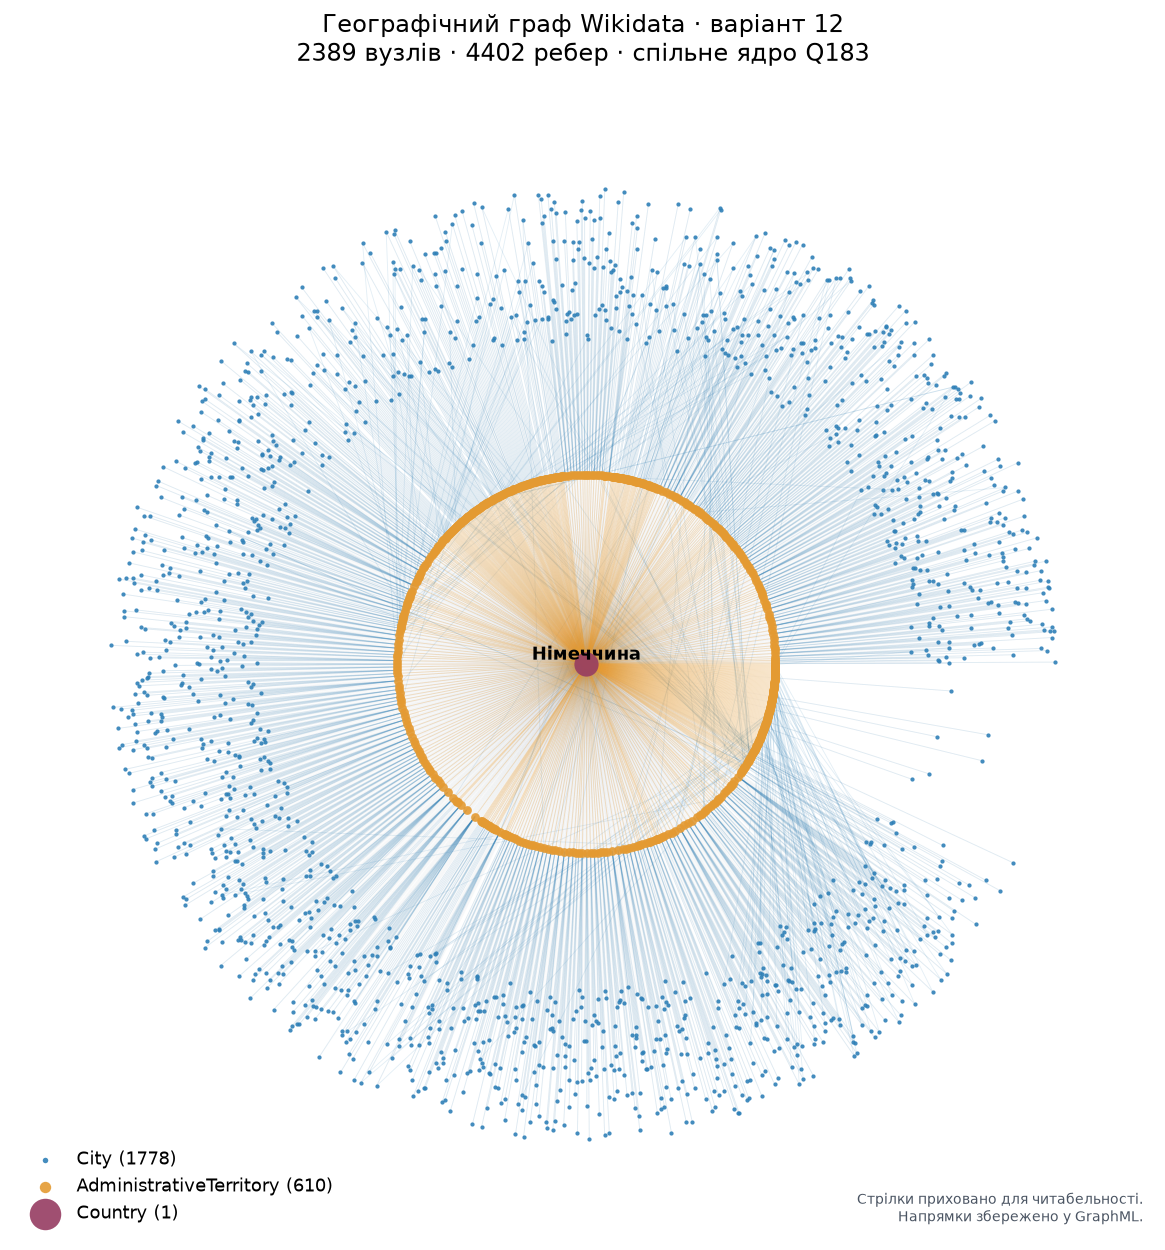

In [8]:
def plot_graph(graph: nx.MultiDiGraph, config: GraphConfig = DEFAULT_CONFIG) -> Figure:
    cities = {node for node, data in graph.nodes(data=True) if data["type"] == "City"}
    admins = {
        node
        for node, data in graph.nodes(data=True)
        if data["type"] == "AdministrativeTerritory"
    }
    groups: dict[str, list[str]] = defaultdict(list)
    for city in sorted(cities):
        parents = sorted(
            v
            for _, v, d in graph.out_edges(city, data=True)
            if d["relation"] == "CityAdmin"
        )
        groups[parents[0]].append(city)
    positions = {config.country: np.zeros(2)}
    slots = sum(max(len(groups.get(admin, [])), 1) + 1 for admin in admins)
    cursor = 0
    rng = np.random.default_rng(config.seed)
    for admin in sorted(admins):
        members = groups.get(admin, [])
        width = max(len(members), 1)
        angle = 2 * np.pi * (cursor + width / 2) / slots
        positions[admin] = 1.05 * np.array([np.cos(angle), np.sin(angle)])
        for offset, city in enumerate(members):
            angle = 2 * np.pi * (cursor + offset + 0.5) / slots
            positions[city] = rng.uniform(1.8, 2.65) * np.array(
                [np.cos(angle), np.sin(angle)]
            )
        cursor += width + 1
    figure, axes = plt.subplots(figsize=(13, 11))
    for relation, color, alpha in (
        ("CityCountry", "#8493A3", 0.045),
        ("CityAdmin", "#2F80B7", 0.13),
        ("AdminCountry", "#E49A32", 0.28),
    ):
        edges = [
            (u, v) for u, v, d in graph.edges(data=True) if d["relation"] == relation
        ]
        nx.draw_networkx_edges(
            graph,
            positions,
            edgelist=edges,
            edge_color=color,
            alpha=alpha,
            width=0.55,
            arrows=False,
            ax=axes,
        )
    for node_type, color, size in (
        ("City", "#2F80B7", 7),
        ("AdministrativeTerritory", "#E49A32", 30),
        ("Country", "#963C62", 230),
    ):
        nodes = [
            node for node, data in graph.nodes(data=True) if data["type"] == node_type
        ]
        nx.draw_networkx_nodes(
            graph,
            positions,
            nodelist=nodes,
            node_size=size,
            node_color=color,
            alpha=0.9,
            linewidths=0,
            label=f"{node_type} ({len(nodes)})",
            ax=axes,
        )
    nx.draw_networkx_labels(
        graph,
        positions,
        labels={config.country: graph.nodes[config.country]["label"]},
        font_size=11,
        font_weight="bold",
        verticalalignment="bottom",
        ax=axes,
    )
    axes.set_title(
        f"Географічний граф Wikidata · варіант 12\n"
        f"{len(graph)} вузлів · {graph.number_of_edges()} ребер · спільне ядро Q183",
        fontsize=15,
        pad=18,
    )
    axes.legend(loc="lower left", frameon=False, markerscale=1.3)
    axes.text(
        0.99,
        0.015,
        "Стрілки приховано для читабельності.\nНапрямки збережено у GraphML.",
        transform=axes.transAxes,
        ha="right",
        fontsize=9,
        color="#4B5563",
    )
    axes.set_aspect("equal")
    axes.axis("off")
    figure.tight_layout()
    return figure

figure = plot_graph(G, config)
figure.savefig(OUT / "graph.png", dpi=180, bbox_inches="tight")
plt.show()

In [9]:
display(Markdown(
    f"**Висновок до завдання 3.** Побудовано MultiDiGraph із "
    f"**{G.number_of_nodes()} вузлів та {G.number_of_edges()} ребер**. "
    "Є рівно три типи вузлів і три типізовані відношення. "
    "Ізольованих вузлів і петель немає; мінімальний степінь не менший за 2. "
    "Граф має одну слабку компоненту зв'язності. Сильна зв'язність відсутня, "
    "оскільки напрямки описують ієрархію, а Country є стоком. "
    "Результат збережено у GraphML та JSON; рисунок охоплює всі сутності."))

**Висновок до завдання 3.** Побудовано MultiDiGraph із **2389 вузлів та 4402 ребер**. Є рівно три типи вузлів і три типізовані відношення. Ізольованих вузлів і петель немає; мінімальний степінь не менший за 2. Граф має одну слабку компоненту зв'язності. Сильна зв'язність відсутня, оскільки напрямки описують ієрархію, а Country є стоком. Результат збережено у GraphML та JSON; рисунок охоплює всі сутності.

## Завдання 4 Глобальні метрики та найкоротші шляхи

Степені та орієнтована щільність обчислюються на `G`; кластеризація та
неорієнтовані відстані — на простій проєкції `H`. Для порівняння наведено
також щільність `H`. Щільність орієнтованого графа без петель:
\(d_G=m/[n(n-1)]\); для `H`: \(d_H=2m_H/[n(n-1)]\).

Відстані рахуються точно, потоковим накопиченням частот довжин, без
збереження матриці всіх пар. Для `H` беруться всі впорядковані пари
**різних** вузлів; для `D` — лише досяжні пари. Частка досяжних напрямлених
пар показується окремо. Середній шлях по всіх напрямлених парах для цього
графа не має скінченного значення, тому що він не є сильно зв'язним.

In [10]:
def path_statistics(graph: nx.Graph) -> dict[str, Any]:
    """Count exact distances between distinct reachable ordered pairs."""
    histogram: Counter[int] = Counter()
    for source, distances in nx.all_pairs_shortest_path_length(graph):
        histogram.update(
            length for target, length in distances.items() if target != source
        )
    pairs = sum(histogram.values())
    if not pairs:
        raise ValueError("The graph has no reachable pair of distinct nodes")
    possible = len(graph) * (len(graph) - 1)
    return {
        "min": min(histogram),
        "max": max(histogram),
        "mean": sum(length * count for length, count in histogram.items()) / pairs,
        "reachable_ordered_pairs": pairs,
        "possible_ordered_pairs": possible,
        "reachable_fraction": pairs / possible,
        "length_histogram": dict(sorted(histogram.items())),
    }


def calculate_global_metrics(
    graph: nx.MultiDiGraph,
) -> tuple[dict[str, Any], dict[str, Any], dict[str, Any]]:
    undirected = nx.Graph(graph)
    degrees = np.array([degree for _, degree in graph.degree()])
    metrics = {
        "nodes": len(graph),
        "edges": graph.number_of_edges(),
        "density_directed": nx.density(graph),
        "density_undirected": nx.density(undirected),
        "degree_mean": float(degrees.mean()),
        "degree_min": int(degrees.min()),
        "degree_max": int(degrees.max()),
        "in_degree_mean": float(np.mean([d for _, d in graph.in_degree()])),
        "out_degree_mean": float(np.mean([d for _, d in graph.out_degree()])),
        "average_clustering_undirected": nx.average_clustering(undirected),
        "transitivity_undirected": nx.transitivity(undirected),
        "weak_components": nx.number_weakly_connected_components(graph),
        "strong_components": nx.number_strongly_connected_components(graph),
        "isolates": len(list(nx.isolates(graph))),
    }
    return metrics, path_statistics(undirected), path_statistics(nx.DiGraph(graph))

global_metrics, paths_undirected, paths_directed = calculate_global_metrics(G)
degrees = dict(G.degree())
degree_values = np.array(list(degrees.values()))
display(pd.DataFrame(global_metrics.items(), columns=["Метрика", "Значення"]))
display(pd.DataFrame({"Неорієнтована H": paths_undirected,
                      "Орієнтована D (досяжні пари)": paths_directed}).drop(index="length_histogram"))

,Метрика,Значення
0,nodes,2389.000000
1,edges,4402.000000
2,density_directed,0.000772
3,density_undirected,0.001543
4,degree_mean,3.685224
5,degree_min,2.000000
6,degree_max,2388.000000
7,in_degree_mean,1.842612
8,out_degree_mean,1.842612
9,average_clustering_undirected,0.884873


,Неорієнтована H,Орієнтована D (досяжні пари)
min,1,1
max,2,1
mean,1.998457,1.0
reachable_ordered_pairs,5704932,4402
possible_ordered_pairs,5704932,5704932
reachable_fraction,1.0,0.000772


In [11]:
display(Markdown(
    f"**Висновок до завдання 4.** Орієнтована щільність становить "
    f"{global_metrics['density_directed']:.6f}; середній/мінімальний/максимальний "
    f"степені — {global_metrics['degree_mean']:.3f} / "
    f"{global_metrics['degree_min']} / {global_metrics['degree_max']}. "
    f"Середня кластеризація H — {global_metrics['average_clustering_undirected']:.4f}. "
    f"Неорієнтовані шляхи мають мінімум {paths_undirected['min']}, "
    f"максимум {paths_undirected['max']} та середнє {paths_undirected['mean']:.4f}. "
    "Діаметр 2 випливає з вибору єдиного ядра: кожний вузол має P17 до країни. "
    "Для досяжних напрямлених пар усі найкоротші шляхи мають довжину 1: "
    "двокроковий шлях City → Admin → Country завжди має прямий City → Country. "
    f"Досяжні лише {paths_directed['reachable_fraction']:.3%} усіх напрямлених пар. "
    "Отже, короткі шляхи та трикутники тут значною мірою задані схемою вибірки."))

**Висновок до завдання 4.** Орієнтована щільність становить 0.000772; середній/мінімальний/максимальний степені — 3.685 / 2 / 2388. Середня кластеризація H — 0.8849. Неорієнтовані шляхи мають мінімум 1, максимум 2 та середнє 1.9985. Діаметр 2 випливає з вибору єдиного ядра: кожний вузол має P17 до країни. Для досяжних напрямлених пар усі найкоротші шляхи мають довжину 1: двокроковий шлях City → Admin → Country завжди має прямий City → Country. Досяжні лише 0.077% усіх напрямлених пар. Отже, короткі шляхи та трикутники тут значною мірою задані схемою вибірки.

## Завдання 5 Центральності вузлів

Degree Centrality, точне Betweenness Centrality та PageRank обчислюються
для напрямленого графа. Degree Centrality враховує сумарний вхідний та
вихідний степінь і нормується на n−1. PageRank використовує `alpha=0.85`,
рівномірну телепортацію та стандартний розподіл для стоків.

Додатково обчислюється точне посередництво на `H`: це дає змогу оцінити
структурну роль ядра. Значення на `G` і `H` мають різний зміст і
показуються в окремих стовпцях. Вибіркова апроксимація не застосовується.

In [12]:
def calculate_centrality(graph: nx.MultiDiGraph) -> pd.DataFrame:
    degree = nx.degree_centrality(graph)
    directed_betweenness = nx.betweenness_centrality(
        graph, normalized=True, weight=None
    )
    undirected_betweenness = nx.betweenness_centrality(
        nx.Graph(graph), normalized=True, weight=None
    )
    pagerank = nx.pagerank(graph, alpha=0.85, tol=1e-12, max_iter=1000, weight=None)
    return pd.DataFrame(
        [
            {
                "qid": node,
                "label": data["label"],
                "type": data["type"],
                "degree": graph.degree(node),
                "degree_centrality": degree[node],
                "betweenness_directed": directed_betweenness[node],
                "betweenness_undirected": undirected_betweenness[node],
                "pagerank": pagerank[node],
            }
            for node, data in graph.nodes(data=True)
        ]
    ).set_index("qid")

centrality = calculate_centrality(G)
pagerank = centrality.pagerank.to_dict()
betweenness_undirected = centrality.betweenness_undirected.to_dict()
for metric, title in (("degree_centrality", "Degree Centrality"), ("pagerank", "PageRank"),
                       ("betweenness_undirected", "Betweenness на H")):
    display(Markdown(f"**Топ 10 за {title}**"))
    display(centrality.sort_values([metric, "label"], ascending=[False, True])
            [["label", "type", "degree", metric]].head(10))
print("Напрямлене Betweenness: min =", centrality.betweenness_directed.min(),
      "; max =", centrality.betweenness_directed.max())

**Топ 10 за Degree Centrality**

,label,type,degree,degree_centrality
qid,,,,
Q183,Німеччина,Country,2388,1.000000
Q6339,Рудні Гори,AdministrativeTerritory,28,0.011725
Q6308,Лейпциг,AdministrativeTerritory,20,0.008375
Q7166,Хайльбронн,AdministrativeTerritory,19,0.007956
Q8541,Людвігсбург,AdministrativeTerritory,18,0.007538
Q6337,Фогтланд,AdministrativeTerritory,17,0.007119
Q6317,Герліц,AdministrativeTerritory,16,0.006700
Q8191,Ортенау,AdministrativeTerritory,16,0.006700
Q8200,Вальдсхут,AdministrativeTerritory,15,0.006281


**Топ 10 за PageRank**

,label,type,degree,pagerank
qid,,,,
Q183,Німеччина,Country,2388,0.375838
Q6339,Рудні Гори,AdministrativeTerritory,28,0.002451
Q6308,Лейпциг,AdministrativeTerritory,20,0.001783
Q6337,Фогтланд,AdministrativeTerritory,17,0.001533
Q8541,Людвігсбург,AdministrativeTerritory,18,0.001449
Q6317,Герліц,AdministrativeTerritory,16,0.001421
Q8191,Ортенау,AdministrativeTerritory,16,0.001394
Q7166,Хайльбронн,AdministrativeTerritory,19,0.001366
Q6330,Цвікау,AdministrativeTerritory,15,0.001366


**Топ 10 за Betweenness на H**

,label,type,degree,betweenness_undirected
qid,,,,
Q183,Німеччина,Country,2388,0.998286
Q6339,Рудні Гори,AdministrativeTerritory,28,0.000062
Q6308,Лейпциг,AdministrativeTerritory,20,0.000030
Q7166,Хайльбронн,AdministrativeTerritory,19,0.000027
Q8541,Людвігсбург,AdministrativeTerritory,18,0.000024
Q6337,Фогтланд,AdministrativeTerritory,17,0.000021
Q6317,Герліц,AdministrativeTerritory,16,0.000018
Q8191,Ортенау,AdministrativeTerritory,16,0.000018
Q6330,Цвікау,AdministrativeTerritory,15,0.000016


Напрямлене Betweenness: min = 0.0 ; max = 0.0


In [13]:
leader = centrality.pagerank.idxmax()
bridge = centrality.betweenness_undirected.idxmax()
display(Markdown(
    f"**Висновок до завдання 5.** Найвищий PageRank має "
    f"{G.nodes[leader]['label']} ({leader}): {pagerank[leader]:.6f}. "
    f"Лідер посередництва в H — {G.nodes[bridge]['label']} ({bridge}), "
    f"значення {betweenness_undirected[bridge]:.6f}. "
    "Напрямлене посередництво всіх вузлів дорівнює нулю: жоден вузол "
    "не лежить усередині найкоротшого напрямленого шляху, бо всі досяжні "
    "пари вже сполучені прямим ребром. Це властивість схеми, а не помилка "
    "обчислення. Високий ранг країни відображає структуру вибірки й "
    "не є незалежною оцінкою значущості географічного об'єкта. "
    "Повні значення для кожного вузла збережено в CSV."))

**Висновок до завдання 5.** Найвищий PageRank має Німеччина (Q183): 0.375838. Лідер посередництва в H — Німеччина (Q183), значення 0.998286. Напрямлене посередництво всіх вузлів дорівнює нулю: жоден вузол не лежить усередині найкоротшого напрямленого шляху, бо всі досяжні пари вже сполучені прямим ребром. Це властивість схеми, а не помилка обчислення. Високий ранг країни відображає структуру вибірки й не є незалежною оцінкою значущості географічного об'єкта. Повні значення для кожного вузла збережено в CSV.

## Завдання 6 Семантичні метрики

Для типів вузлів і типізованих відношень обчислюються кількості, частки,
ентропія Шеннона, нормована ентропія та індекс різноманітності Сімпсона:

\[
H=-\sum_{i=1}^{3}p_i\log_2p_i,\qquad
H_{\mathrm{norm}}=H/\log_2 3,\qquad
D_{\mathrm{Simpson}}=1-\sum_{i=1}^{3}p_i^2.
\]

Нормована ентропія лежить у [0,1]; 1 означає рівні частки трьох типів.
Для трьох типів максимум індексу Сімпсона становить 2/3. Окремо
оцінюється локальна нормована ентропія типів інцидентних ребер вузла
з урахуванням вхідних і вихідних зв'язків. Це явно визначені показники
розподілу типів, а не довільне відношення двох лічильників.

In [14]:
def distribution(counts: Counter[str]) -> pd.DataFrame:
    total = counts.total()
    if not total:
        raise ValueError("Cannot calculate a distribution from empty counts")
    return pd.DataFrame(
        [
            {
                "Тип": name,
                "Кількість": count,
                "Частка": count / total,
                "Відсоток": 100 * count / total,
            }
            for name, count in sorted(counts.items())
        ]
    )


def diversity(counts: Counter[str], vocabulary_size: int = 3) -> dict[str, float]:
    if (
        vocabulary_size < 2
        or not counts
        or any(count <= 0 for count in counts.values())
    ):
        raise ValueError(
            "Diversity requires positive counts and at least two possible types"
        )
    probabilities = np.array(list(counts.values()), dtype=float)
    probabilities /= probabilities.sum()
    entropy = float(-np.sum(probabilities * np.log2(probabilities)))
    return {
        "entropy_bits": entropy,
        "normalized_entropy": entropy / math.log2(vocabulary_size),
        "simpson_diversity": float(1 - np.sum(probabilities**2)),
    }


def calculate_semantic_metrics(
    graph: nx.MultiDiGraph,
) -> tuple[pd.DataFrame, pd.DataFrame, dict[str, Any], dict[str, float]]:
    nodes = Counter(data["type"] for _, data in graph.nodes(data=True))
    relations = Counter(data["relation"] for *_, data in graph.edges(data=True))
    local = {}
    for node in graph:
        counts = Counter(d["relation"] for *_, d in graph.in_edges(node, data=True))
        counts.update(d["relation"] for *_, d in graph.out_edges(node, data=True))
        local[node] = diversity(counts)["normalized_entropy"]
    metrics = {
        "node_types": diversity(nodes),
        "relation_types": diversity(relations),
        "local_relation_diversity_mean": float(np.mean(list(local.values()))),
    }
    return distribution(nodes), distribution(relations), metrics, local

node_distribution, relation_distribution, semantic_metrics, local_diversity = calculate_semantic_metrics(G)
node_counts = Counter(d["type"] for _, d in G.nodes(data=True))
property_counts = Counter(d["property"] for *_, d in G.edges(data=True))
centrality["local_relation_diversity"] = pd.Series(local_diversity)
display(Markdown("**Типи вузлів**"))
display(node_distribution)
display(Markdown("**Типізовані відношення**"))
display(relation_distribution)
display(Markdown("**Предикати Wikidata**"))
display(distribution(property_counts))
display(pd.DataFrame({key: semantic_metrics[key] for key in ("node_types", "relation_types")}).T)
display(centrality.groupby("type")["local_relation_diversity"].agg(["mean", "min", "max"]))

**Типи вузлів**

,Тип,Кількість,Частка,Відсоток
0,AdministrativeTerritory,610,0.255337,25.533696
1,City,1778,0.744244,74.424445
2,Country,1,0.000419,0.041859


**Типізовані відношення**

,Тип,Кількість,Частка,Відсоток
0,AdminCountry,610,0.138573,13.857338
1,CityAdmin,2014,0.457519,45.751931
2,CityCountry,1778,0.403907,40.390731


**Предикати Wikidata**

,Тип,Кількість,Частка,Відсоток
0,P131,2014,0.457519,45.751931
1,P17,2388,0.542481,54.248069


,entropy_bits,normalized_entropy,simpson_diversity
node_types,0.824751,0.520360,0.380903
relation_types,1.439509,0.908229,0.608332


,mean,min,max
type,,,
AdministrativeTerritory,0.524087,0.140246,0.630930
City,0.624007,0.410118,0.630930
Country,0.517232,0.517232,0.517232


In [15]:
display(Markdown(
    f"**Висновок до завдання 6.** Найчисленніший тип вузлів — "
    f"{node_counts.most_common(1)[0][0]}; Country представлено одним ядром. "
    f"Нормована ентропія типів вузлів становить "
    f"{semantic_metrics['node_types']['normalized_entropy']:.4f}, "
    f"відношень — {semantic_metrics['relation_types']['normalized_entropy']:.4f}. "
    "Дисбаланс типів очікуваний: багато міст належать до меншої кількості "
    "адміністративних одиниць і до однієї країни. Облік лише P17 та P131 "
    "об'єднав би два різні семантичні відношення, тому розподіл предикатів "
    "наведено додатково. Суми часток вузлів і відношень перевірено: вони дорівнюють 1."))

**Висновок до завдання 6.** Найчисленніший тип вузлів — City; Country представлено одним ядром. Нормована ентропія типів вузлів становить 0.5204, відношень — 0.9082. Дисбаланс типів очікуваний: багато міст належать до меншої кількості адміністративних одиниць і до однієї країни. Облік лише P17 та P131 об'єднав би два різні семантичні відношення, тому розподіл предикатів наведено додатково. Суми часток вузлів і відношень перевірено: вони дорівнюють 1.

## Завдання 7 Розподіл степенів і властивості графа знань

Побудовано гістограму в області малих степенів та повний розподіл у
логарифмічних координатах. Межа першої панелі й кількість вузлів поза нею
підписані явно. Третя панель — емпірична CCDF P(K ≥ k), яка охоплює
всі вузли, включно з країною та адміністративними хабами.

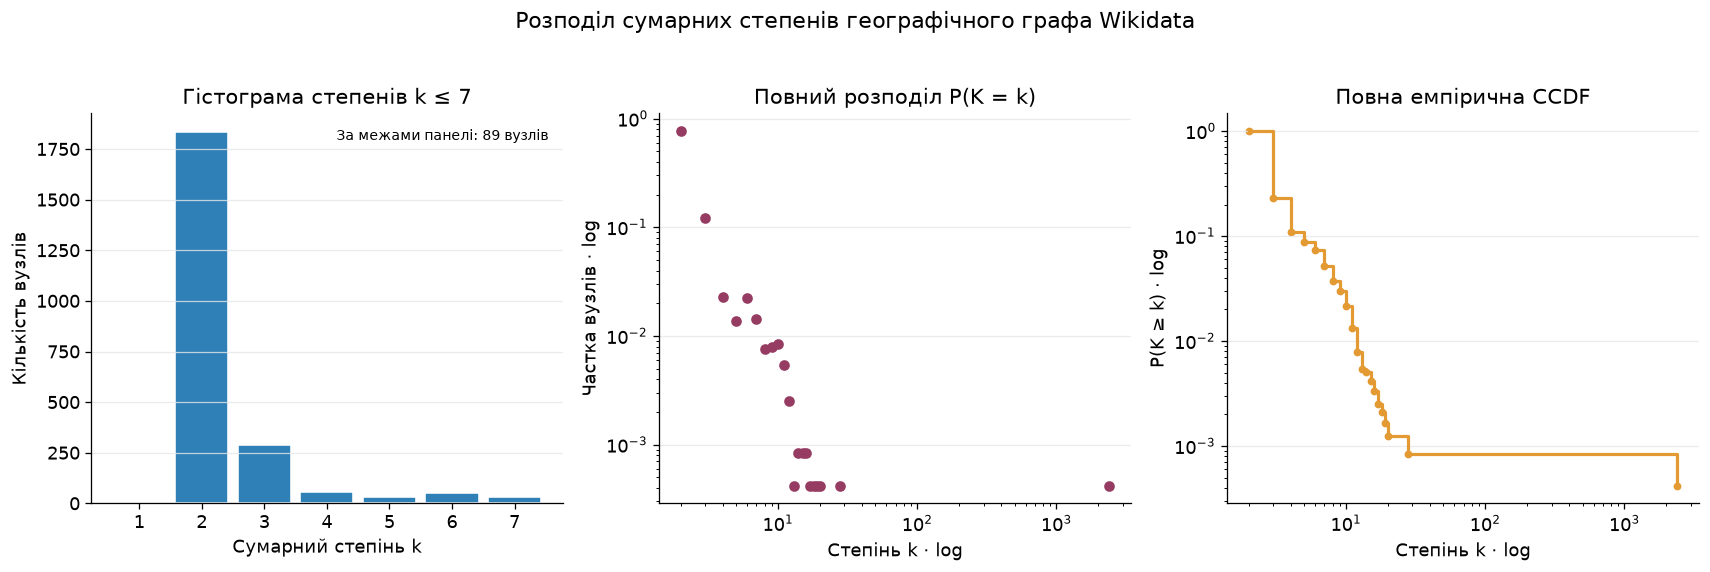

,degree,count,fraction,ccdf
0,2,1835,0.768104,1.000000
1,3,290,0.121390,0.231896
2,4,55,0.023022,0.110506
3,5,33,0.013813,0.087484
4,6,53,0.022185,0.073671
5,7,34,0.014232,0.051486
6,8,18,0.007535,0.037254
7,9,19,0.007953,0.029720
8,10,20,0.008372,0.021766
9,11,13,0.005442,0.013395


In [16]:
def degree_distribution(graph: nx.MultiDiGraph) -> pd.DataFrame:
    degrees = np.array([degree for _, degree in graph.degree()])
    counts = Counter(degrees.tolist())
    return pd.DataFrame(
        [
            {
                "degree": degree,
                "count": counts[degree],
                "fraction": counts[degree] / len(graph),
                "ccdf": float(np.mean(degrees >= degree)),
            }
            for degree in sorted(counts)
        ]
    )


def plot_degree_distribution(
    graph: nx.MultiDiGraph, frequencies: pd.DataFrame
) -> Figure:
    degrees = np.array([degree for _, degree in graph.degree()])
    low_limit = max(6, min(20, int(np.quantile(degrees, 0.95))))
    figure, axes = plt.subplots(1, 3, figsize=(15, 4.8))
    axes[0].hist(
        degrees[degrees <= low_limit],
        bins=np.arange(0.5, low_limit + 1.5),
        color="#2F80B7",
        edgecolor="white",
        rwidth=0.85,
    )
    axes[0].set(
        title=f"Гістограма степенів k ≤ {low_limit}",
        xlabel="Сумарний степінь k",
        ylabel="Кількість вузлів",
    )
    axes[0].text(
        0.97,
        0.96,
        f"За межами панелі: {int(np.sum(degrees > low_limit))} вузлів",
        ha="right",
        va="top",
        transform=axes[0].transAxes,
        fontsize=9,
    )
    axes[1].scatter(frequencies.degree, frequencies.fraction, s=32, color="#963C62")
    axes[1].set(
        xscale="log",
        yscale="log",
        title="Повний розподіл P(K = k)",
        xlabel="Степінь k · log",
        ylabel="Частка вузлів · log",
    )
    axes[2].step(
        frequencies.degree, frequencies.ccdf, where="post", color="#E49A32", linewidth=2
    )
    axes[2].scatter(frequencies.degree, frequencies.ccdf, s=15, color="#E49A32")
    axes[2].set(
        xscale="log",
        yscale="log",
        title="Повна емпірична CCDF",
        xlabel="Степінь k · log",
        ylabel="P(K ≥ k) · log",
    )
    for axis in axes:
        axis.grid(axis="y", color="#E5E7EB", alpha=0.8)
    figure.suptitle(
        "Розподіл сумарних степенів географічного графа Wikidata", fontsize=14, y=1.03
    )
    figure.tight_layout()
    return figure

frequencies = degree_distribution(G)
degree_frequency = Counter(degree_values.tolist())
figure = plot_degree_distribution(G, frequencies)
figure.savefig(OUT / "degree_distribution.png", dpi=180, bbox_inches="tight")
plt.show()
display(frequencies)

In [17]:
mode_degree, mode_count = degree_frequency.most_common(1)[0]
display(Markdown(
    f"**Висновок до завдання 7.** Найчастіший степінь — {mode_degree}: "
    f"{mode_count} вузлів ({mode_count / len(G):.2%}). "
    f"Максимальний степінь {degree_values.max()} у "
    f"{degree_values.max() / degree_values.mean():.1f} раза перевищує середній. "
    "Розподіл неоднорідний: більшість міст має мало зв'язків, тоді як країна "
    "та адміністративні одиниці утворюють хаби. Розрідженість, типізовані "
    "сутності та нерівномірні степені узгоджуються з типовими рисами графів знань. "
    "Водночас спільне ядро примусово задає діаметр 2, а трикутники "
    "City–Admin–Country формуються схемою. За виглядом log-log рисунка "
    "не можна довести степеневий закон, безмасштабність чи властивість "
    "малого світу: для таких тверджень потрібні окремі статистичні тести "
    "й порівняння з відповідними випадковими моделями."))

**Висновок до завдання 7.** Найчастіший степінь — 2: 1835 вузлів (76.81%). Максимальний степінь 2388 у 648.0 раза перевищує середній. Розподіл неоднорідний: більшість міст має мало зв'язків, тоді як країна та адміністративні одиниці утворюють хаби. Розрідженість, типізовані сутності та нерівномірні степені узгоджуються з типовими рисами графів знань. Водночас спільне ядро примусово задає діаметр 2, а трикутники City–Admin–Country формуються схемою. За виглядом log-log рисунка не можна довести степеневий закон, безмасштабність чи властивість малого світу: для таких тверджень потрібні окремі статистичні тести й порівняння з відповідними випадковими моделями.

## Підсумок і відтворюваність

Виконано сім завдань: сформовано числову SPARQL-вибірку, отримано та
перевірено справжні сутності Wikidata, побудовано типізований MultiDiGraph,
обчислено глобальні, локальні та семантичні метрики, створено візуалізацію
і досліджено степені. Висновки стосуються цього підграфа, а не всієї Wikidata.

Обмеження: вибірка містить одну країну; `LIMIT` та стабільний порядок за URI
не утворюють випадкову репрезентативну вибірку. Відсутні у Wikidata твердження
не відновлюються припущеннями. Поле P1082 не гарантує актуального населення.
Схема ролей усуває багатотипність, а напрямленість робить частину пар
недосяжними. Результати нового завантаження можуть відрізнятися через
редагування Wikidata; вбудований знімок фіксує дані цієї роботи.

Усі вихідні файли створюються відносно каталогу запуску. Для відтворення
цього аналізу достатньо самого ноутбука та встановлених залежностей.

In [18]:
def export_results(
    result: AnalysisResult,
    snapshot: dict[str, Any],
    output: Path,
    *,
    plots: bool = True,
) -> None:
    output.mkdir(parents=True, exist_ok=True)
    graph = result.graph
    nx.write_graphml(graph, output / "variant12_geography.graphml")
    write_json(
        output / "variant12_geography.json", nx.node_link_data(graph, edges="edges")
    )
    write_json(output / "wikidata_snapshot.json", snapshot)
    (output / "query.rq").write_text(QUERY, encoding="utf-8", newline="\n")
    for filename, table, index in (
        ("centrality_all_nodes.csv", result.centrality, True),
        ("node_type_distribution.csv", result.node_distribution, False),
        ("relation_type_distribution.csv", result.relation_distribution, False),
        ("degree_distribution.csv", result.degrees, False),
    ):
        table.to_csv(
            output / filename, index=index, encoding="utf-8-sig", lineterminator="\n"
        )
    write_json(
        output / "metrics.json",
        {
            "variant": 12,
            "domain": 5,
            "filter_variant": "A",
            "global": result.global_metrics,
            "paths_undirected": result.paths_undirected,
            "paths_directed_reachable": result.paths_directed,
            "semantic": result.semantics,
            "node_type_counts": dict(
                Counter(d["type"] for _, d in graph.nodes(data=True))
            ),
            "relation_type_counts": dict(
                Counter(d["relation"] for *_, d in graph.edges(data=True))
            ),
            "predicate_counts": dict(
                Counter(d["property"] for *_, d in graph.edges(data=True))
            ),
            "sampling": result.sampling,
            "provenance": snapshot["provenance"],
            "versions": versions(),
        },
    )
    if plots:
        for name, figure in (
            ("graph.png", plot_graph(graph)),
            (
                "degree_distribution.png",
                plot_degree_distribution(graph, result.degrees),
            ),
        ):
            figure.savefig(output / name, dpi=180, bbox_inches="tight")
            plt.close(figure)
    write_json(
        output / "sha256.json",
        {
            path.name: hashlib.sha256(path.read_bytes()).hexdigest()
            for path in sorted(output.iterdir())
            if path.is_file() and path.name != "sha256.json"
        },
    )

result = AnalysisResult(G, sampling, global_metrics, paths_undirected, paths_directed,
                        centrality, node_distribution, relation_distribution,
                        semantic_metrics, frequencies)
export_results(result, snapshot, OUT, plots=False)
restored = nx.read_graphml(OUT / "variant12_geography.graphml", force_multigraph=True)
assert restored.is_directed() and restored.is_multigraph()
assert dict(restored.nodes(data=True)) == dict(G.nodes(data=True))
assert {(u, v, k): d for u, v, k, d in restored.edges(keys=True, data=True)} == {
    (u, v, k): d for u, v, k, d in G.edges(keys=True, data=True)}
assert all(restored.graph[key] == value for key, value in G.graph.items())
assert math.isclose(centrality.pagerank.sum(), 1.0, abs_tol=1e-9)
assert centrality.betweenness_directed.eq(0).all()
assert math.isclose(node_distribution["Частка"].sum(), 1.0)
assert math.isclose(relation_distribution["Частка"].sum(), 1.0)
assert paths_undirected["reachable_fraction"] == 1
assert paths_directed["min"] == paths_directed["max"] == 1
print(f"Перевірено: {len(G)} ≥ {MIN_NODES} вузлів; 3 типи вузлів; 3 типи відношень;")
print("1 слабка компонента; 0 ізольованих вузлів; числовий фільтр дотримано.")
print("GraphML повторно прочитано; типи, атрибути, ключі й ребра збігаються.")
for file in sorted(OUT.iterdir()):
    if file.is_file():
        print(f"  {file.name}: {file.stat().st_size:,} байтів")

Перевірено: 2389 ≥ 1500 вузлів; 3 типи вузлів; 3 типи відношень;
1 слабка компонента; 0 ізольованих вузлів; числовий фільтр дотримано.
GraphML повторно прочитано; типи, атрибути, ключі й ребра збігаються.
  centrality_all_nodes.csv: 274,758 байтів
  degree_distribution.csv: 1,014 байтів
  degree_distribution.png: 107,805 байтів
  graph.png: 2,583,568 байтів
  metrics.json: 2,933 байтів
  node_type_distribution.csv: 226 байтів
  query.rq: 552 байтів
  relation_type_distribution.csv: 220 байтів
  sha256.json: 1,045 байтів
  variant12_geography.graphml: 1,350,424 байтів
  variant12_geography.json: 1,413,457 байтів
  wikidata_snapshot.json: 971,469 байтів


## Джерела

1. Умова «Практичне заняття № 7. Wikidata API, SPARQL-вибірки та генерація NetworkX графів у Python».
2. [Wikidata SPARQL tutorial](https://www.wikidata.org/wiki/Wikidata:SPARQL_tutorial) — синтаксис запитів і класифікація міст.
3. [P17 country](https://www.wikidata.org/wiki/Property:P17), [P131 located in the administrative territorial entity](https://www.wikidata.org/wiki/Property:P131), [P1082 population](https://www.wikidata.org/wiki/Property:P1082).
4. [Q515 city](https://www.wikidata.org/wiki/Q515), [Q6256 country](https://www.wikidata.org/wiki/Q6256), [Q56061 administrative territorial entity](https://www.wikidata.org/wiki/Q56061), [Q183 Germany](https://www.wikidata.org/wiki/Q183).
5. [NetworkX MultiDiGraph](https://networkx.org/documentation/stable/reference/classes/multidigraph.html).
6. [Degree Centrality](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.degree_centrality.html), [Betweenness Centrality](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.betweenness_centrality.html), [PageRank](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.link_analysis.pagerank_alg.pagerank.html).
7. [Wikidata Alternative endpoints](https://www.wikidata.org/wiki/Wikidata:SPARQL_query_service/Alternative_endpoints), [QLever Wikidata](https://qlever.dev/wikidata) — фактичний сервіс отримання збереженої SPARQL-відповіді.

Структуровані дані отримано з Wikidata; вони доступні за [CC0](https://www.wikidata.org/wiki/Wikidata:Licensing).
Мітки, дати завантаження, контрольні суми та запит збережено разом із результатами.